<a href="https://colab.research.google.com/github/abbibr/ntcc-medicine/blob/master/NTCC_04_ready_code_nhanes_clinical_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NTCC: Multi-Disease Diagnosis on a Clinical Dataset (NHANES 2013-2014)

**Goal:** the first dataset (BRFSS) had only survey answers. Here we use **NHANES**, which also has **real lab tests**, and check if the models get better.

**What this notebook does (everything in one file):**
1. Load the 4 NHANES files and build one clean dataset
2. Feature engineering (new clinical features)
3. Train the same 4 models as before: Logistic Regression, Random Forest, Linear SVM, XGBoost
4. Compare: with and without lab tests, with and without engineered features
5. Compare NHANES results with the BRFSS results

## 1. Setup and loading the files

In [ ]:
import os, glob, json, time, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
try:
    from xgboost import XGBClassifier
except ImportError:      # Colab usually has xgboost already
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
    from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 50)

# ---- Settings ----
RANDOM_STATE = 42
N_FOLDS      = 5      # cross-validation folds
N_REPEATS    = 2      # repeat the whole cross-validation (different splits) to make results more stable

# ---- Find the 4 files (upload them if they are not in Colab yet) ----
KEYS = {"demo": "demographic", "exam": "examination", "labs": "labs", "quest": "questionnaire"}
def find_file(key):
    hits = [f for f in glob.glob("**/*.csv", recursive=True) if key in os.path.basename(f).lower()]
    return sorted(hits, key=os.path.getmtime, reverse=True)[0] if hits else None

paths = {k: find_file(v) for k, v in KEYS.items()}
if any(p is None for p in paths.values()):
    from google.colab import files
    print("Upload the 4 files: demographic.csv, examination.csv, labs.csv, questionnaire.csv")
    files.upload()
    paths = {k: find_file(v) for k, v in KEYS.items()}
assert all(paths.values()), f"Some files are missing: {paths}"
print(paths)

{'demo': 'demographic.csv', 'exam': 'examination.csv', 'labs': 'labs.csv', 'quest': 'questionnaire.csv'}


## About the dataset

- **NHANES 2013-2014** (US CDC): a national health survey that combines **interviews, physical exams and blood/urine lab tests**.
- Our 4 files describe the same people. They are linked by the column `SEQN` (person ID):
  `demographic` (age, sex, ...), `examination` (BMI, blood pressure, ...), `labs` (blood tests), `questionnaire` (health questions, including doctor-told diseases).
- **10,175 people in total, but the dataset is not ready to use:**
  - Disease questions were asked **only to adults (20+)**: 5,769 people.
  - Answers like 7 = "refused" and 9 = "don't know" are not real values.
  - Some lab tests were done only on a part of the people (fasting sub-sample), so many values are empty.
  - The 4 files must be merged, and the 3 disease labels must be built from questionnaire answers.

So the next section builds a clean dataset.

## 2. Build the dataset

In [ ]:
# columns we need from each file (the files have hundreds of columns we do not use)
DEMO  = ["SEQN","RIAGENDR","RIDAGEYR","RIDRETH1","DMDEDUC2","INDFMPIR"]
EXAM  = ["SEQN","BMXBMI","BMXWAIST","BMXHT","BPXPLS","BPXSY1","BPXSY2","BPXSY3","BPXSY4","BPXDI1","BPXDI2","BPXDI3","BPXDI4"]
LABS  = ["SEQN","LBXGH","LBXSGL","LBXTC","LBDHDD","LBXSTR","LBXSCR","LBXSBU","LBXSATSI","LBXSASSI",
         "LBXSAL","LBXSTB","LBXSUA","LBXHGB","LBXWBCSI","LBXPLTSI"]
QUEST = ["SEQN","DIQ010","MCQ160C","MCQ160E","MCQ160F","BPQ020","BPQ080","SMQ020","HUQ010"]

def read(key, cols):
    return pd.read_csv(paths[key], usecols=lambda c: c in cols, low_memory=False)

raw = read("demo", DEMO)
for key, cols in [("exam", EXAM), ("labs", LABS), ("quest", QUEST)]:
    raw = raw.merge(read(key, cols), on="SEQN", how="left")      # one row per person
print("All people:", raw.shape)

df = raw.copy()

# 1) codes 7 = refused, 9 = don't know -> missing value
for c in ["DMDEDUC2","BPQ020","BPQ080","SMQ020","HUQ010","DIQ010","MCQ160C","MCQ160E","MCQ160F"]:
    df[c] = df[c].replace({7: np.nan, 9: np.nan})
yes_no = {1: 1, 2: 0}      # in NHANES: 1 = yes, 2 = no

# 2) the 3 target diseases (told by a doctor), same idea as in BRFSS
df["Diabetes"]      = df["DIQ010"].map({1: 1, 2: 0, 3: 0})         # 3 = borderline -> 0 (same as BRFSS)
chd, mi             = df["MCQ160C"].map(yes_no), df["MCQ160E"].map(yes_no)
df["Heart disease"] = ((chd == 1) | (mi == 1)).astype(float).where(chd.notna() & mi.notna())   # coronary heart disease or heart attack
df["Stroke"]        = df["MCQ160F"].map(yes_no)

# 3) readable feature names
df = df.rename(columns={
    "RIDAGEYR":"Age","RIDRETH1":"Race","DMDEDUC2":"Education","INDFMPIR":"IncomeRatio",
    "BMXBMI":"BMI","BMXWAIST":"Waist","BMXHT":"Height","BPXPLS":"Pulse",
    "BPXSY1":"SBP1","BPXSY2":"SBP2","BPXSY3":"SBP3","BPXSY4":"SBP4","BPXDI1":"DBP1","BPXDI2":"DBP2","BPXDI3":"DBP3","BPXDI4":"DBP4",
    "LBXGH":"HbA1c","LBXSGL":"Glucose","LBXTC":"TotalChol","LBDHDD":"HDL","LBXSTR":"Triglycerides","LBXSCR":"Creatinine",
    "LBXSBU":"BUN","LBXSATSI":"ALT","LBXSASSI":"AST","LBXSAL":"Albumin","LBXSTB":"Bilirubin","LBXSUA":"UricAcid",
    "LBXHGB":"Hemoglobin","LBXWBCSI":"WBC","LBXPLTSI":"Platelets",
    "BPQ020":"HighBP","BPQ080":"HighChol","HUQ010":"GenHlth"})
df["Male"]   = (df["RIAGENDR"] == 1).astype(int)
df["Smoker"] = df["SMQ020"].map(yes_no)          # smoked at least 100 cigarettes in life

# 4) keep adults (20+) whose 3 disease answers are known
TARGETS = ["Diabetes", "Heart disease", "Stroke"]
df["HighBP"]  = df["HighBP"].map(yes_no);  df["HighChol"] = df["HighChol"].map(yes_no)
df = df[df["Age"] >= 20].dropna(subset=TARGETS).reset_index(drop=True)
df[TARGETS] = df[TARGETS].astype(int)

summary = pd.DataFrame({"people with disease": df[TARGETS].sum(), "rate": df[TARGETS].mean().round(4)})
print("Final dataset:", len(df), "adults")
display(summary)

All people: (10175, 41)
Final dataset: 5742 adults


,people with disease,rate
Diabetes,714,0.1243
Heart disease,344,0.0599
Stroke,196,0.0341


**What we did:**
- Merged 4 files into one table (one row per person).
- Replaced "refused" and "don't know" answers with empty values.
- Built 3 labels: **Diabetes**, **Heart disease** (coronary heart disease or heart attack) and **Stroke**. They are the same diseases as in BRFSS.
- Kept only adults with known answers. The final dataset is small (about 5,700 people), and stroke has only about 200 cases.
  Because of this, we will use **cross-validation** instead of one test set (a small test set would have only ~30 stroke cases, too noisy).

## 3. Quick look: which values are missing?

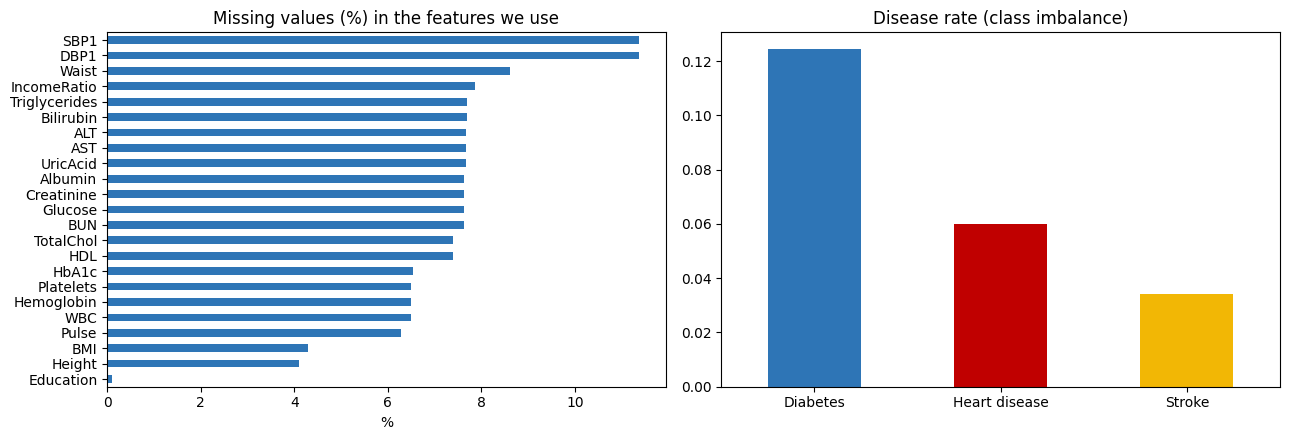

Not used: LDL cholesterol and fasting triglycerides (LBDLDL, LBXTR) are empty for ~56% of people (only a fasting sub-sample).
We use serum triglycerides (LBXSTR) instead: only ~8% missing.


In [ ]:
lab_cols = ["HbA1c","Glucose","TotalChol","HDL","Triglycerides","Creatinine","BUN","ALT","AST","Albumin","Bilirubin","UricAcid","Hemoglobin","WBC","Platelets"]
body_cols = ["BMI","Waist","Height","Pulse","SBP1","DBP1","IncomeRatio","Education"]
miss = (df[lab_cols + body_cols].isna().mean() * 100).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
miss.plot.barh(ax=ax[0], color="#2E75B6"); ax[0].invert_yaxis(); ax[0].set_title("Missing values (%) in the features we use"); ax[0].set_xlabel("%")
df[TARGETS].mean().plot.bar(ax=ax[1], color=["#2E75B6","#C00000","#F2B705"]); ax[1].set_title("Disease rate (class imbalance)")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig("chart_0_data_overview.png", dpi=150); plt.show()
print("Not used: LDL cholesterol and fasting triglycerides (LBDLDL, LBXTR) are empty for ~56% of people (only a fasting sub-sample).")
print("We use serum triglycerides (LBXSTR) instead: only ~8% missing.")

## 4. Feature engineering

We create **new features from the existing ones**, using simple medical knowledge. The idea: ratios and combined values often describe health better than single measurements.

| New feature | Formula | Why it helps |
|---|---|---|
| `SBP_mean`, `DBP_mean` | average of the 1-4 blood pressure readings | one reading is noisy; the average is more reliable |
| `PulsePressure` | systolic - diastolic pressure | known heart risk indicator |
| `WaistHeight` | waist / height | body fat around the belly; often better than BMI |
| `NonHDL` | total cholesterol - HDL | all "bad" cholesterol together |
| `TC_HDL` | total cholesterol / HDL | classic heart risk ratio |
| `TG_HDL` | triglycerides / HDL | a simple sign of insulin resistance (diabetes risk) |
| `AST_ALT` | AST / ALT | liver enzyme ratio |
| `eGFR` | kidney function from creatinine, age and sex (CKD-EPI 2021 formula) | shows how well the kidneys work |

In [ ]:
def add_features(d):
    d = d.copy()
    d["SBP_mean"]      = d[["SBP1","SBP2","SBP3","SBP4"]].mean(axis=1)      # average of available readings
    d["DBP_mean"]      = d[["DBP1","DBP2","DBP3","DBP4"]].mean(axis=1)
    d["PulsePressure"] = d["SBP_mean"] - d["DBP_mean"]
    d["WaistHeight"]   = d["Waist"] / d["Height"]
    d["NonHDL"]        = d["TotalChol"] - d["HDL"]
    d["TC_HDL"]        = d["TotalChol"] / d["HDL"]
    d["TG_HDL"]        = d["Triglycerides"] / d["HDL"]
    d["AST_ALT"]       = d["AST"] / d["ALT"]
    # eGFR, CKD-EPI 2021 formula
    female = d["Male"] == 0
    kappa  = np.where(female, 0.7, 0.9)
    alpha  = np.where(female, -0.241, -0.302)
    ratio  = d["Creatinine"] / kappa
    d["eGFR"] = 142 * np.minimum(ratio, 1) ** alpha * np.maximum(ratio, 1) ** -1.200 * 0.9938 ** d["Age"] * np.where(female, 1.012, 1.0)
    return d.replace([np.inf, -np.inf], np.nan)

df = add_features(df)
ENG = ["SBP_mean","DBP_mean","PulsePressure","WaistHeight","NonHDL","TC_HDL","TG_HDL","AST_ALT","eGFR"]
print("New features added:", ENG)

# Does the new feature separate sick and healthy people better than its raw parts?
# We use the ROC-AUC of each single feature (0.5 = useless, higher = better; direction is ignored).
def single_auc(col, target):
    s = df[[col, target]].dropna()
    a = roc_auc_score(s[target], s[col])
    return max(a, 1 - a)

compare = [("SBP1","SBP_mean"), ("Waist","WaistHeight"), ("Triglycerides","TG_HDL"), ("TotalChol","TC_HDL"),
           ("Creatinine","eGFR"), ("AST","AST_ALT")]
rows = []
for raw_col, new_col in compare:
    for col, kind in [(raw_col, "raw"), (new_col, "NEW")]:
        rows.append({"feature": col, "type": kind, **{t: round(single_auc(col, t), 3) for t in TARGETS}})
auc_table = pd.DataFrame(rows).set_index("feature")
display(auc_table)

New features added: ['SBP_mean', 'DBP_mean', 'PulsePressure', 'WaistHeight', 'NonHDL', 'TC_HDL', 'TG_HDL', 'AST_ALT', 'eGFR']


,type,Diabetes,Heart disease,Stroke
feature,,,,
SBP1,raw,0.645,0.625,0.597
SBP_mean,NEW,0.642,0.608,0.593
Waist,raw,0.710,0.629,0.572
WaistHeight,NEW,0.725,0.628,0.604
Triglycerides,raw,0.642,0.558,0.511
TG_HDL,NEW,0.652,0.573,0.519
TotalChol,raw,0.599,0.632,0.576
TC_HDL,NEW,0.532,0.529,0.537
Creatinine,raw,0.579,0.696,0.661


How to read the table: each row is one feature used **alone**. A higher number means the feature separates sick and healthy people better.
Compare each `raw` feature with the `NEW` one under it.

What we see: some new features are better alone (`WaistHeight`, `TG_HDL`, `eGFR`), but not all (`TC_HDL` is weaker than `TotalChol`). Also, `eGFR` is strong partly because its formula uses **age**.
So a good single feature does not always improve the models. We test the engineered features inside the models in section 6.

## 5. Three feature sets

To see what really helps, we train every model on 3 sets of features:

1. **Basic (no labs):** age, sex, race, education, income, BMI, waist, pulse, blood pressure, smoking, general health, doctor-told high BP / high cholesterol. This is similar to the BRFSS data.
2. **+ Labs:** the basic set plus 15 lab tests (HbA1c, glucose, cholesterol, kidney, liver, blood count, ...).
3. **+ Engineered:** the previous set plus the 9 new features from section 4.

**Important:** HbA1c and glucose are almost the *definition* of diabetes. A big improvement for diabetes with labs is expected, but it is partly "easy". Heart disease and stroke are a fairer test.
We never use medicines or diabetes-treatment questions (that would be data leakage).

In [ ]:
BASIC = ["Age","Male","Race","Education","IncomeRatio","BMI","Waist","Pulse","SBP1","DBP1","HighBP","HighChol","Smoker","GenHlth"]
LABS_ = lab_cols
FEATURE_SETS = {"1 Basic (no labs)": BASIC,
                "2 + Labs":          BASIC + LABS_,
                "3 + Engineered":    BASIC + LABS_ + ENG}
for k, v in FEATURE_SETS.items(): print(f"{k:20s} {len(v)} features")

1 Basic (no labs)    14 features
2 + Labs             29 features
3 + Engineered       38 features


## 6. Training and testing the models

**How we test (5-fold cross-validation, repeated):**
- The people are split into 5 parts. We train on 4 parts and predict the 5th part. This is done 5 times, so **every person is predicted by a model that never saw him/her**.
- We repeat this with different random splits (`N_REPEATS`) and average the results. All models use the **same splits**, so the comparison is fair.
- Missing values are filled with the median and numbers are scaled **inside** each fold (the pipeline learns them only from the training part: no data leakage).
- Metrics: **ROC-AUC** and **PR-AUC** (main, honest ones), plus precision / recall / F1 at the best threshold.
  Note: the best threshold is chosen on the same predictions, so precision/recall/F1 are a little optimistic. This is the same for all models.

In [ ]:
strat_key = (df["Diabetes"]*4 + df["Heart disease"]*2 + df["Stroke"]).values    # keeps the 3 disease rates similar in every fold
all_rows, curves = [], {}

def make_pipeline(model, cols, scale):
    num = [c for c in cols if c != "Race"]
    num_steps = [("fill", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    parts = [("num", Pipeline(num_steps), num)]
    if "Race" in cols:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore"), ["Race"]))     # race is a category, not a number
    return Pipeline([("prep", ColumnTransformer(parts)), ("model", model)])

def get_score(pipe, X):
    m = pipe.named_steps["model"]
    return pipe.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else pipe.decision_function(X)

def scores(y, s):
    p, r, th = precision_recall_curve(y, s)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    i = np.argmax(f1)
    return {"ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
            "Precision": p[i], "Recall": r[i], "F1": f1[i]}

def run_model(name, make_model, scale):
    rows = []
    for fs_name, cols in FEATURE_SETS.items():
        for target in TARGETS:
            y, X = df[target].values, df[cols]
            t0, per_repeat = time.time(), []
            for rep in range(N_REPEATS):
                oof = np.zeros(len(df))                                   # out-of-fold predictions
                skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=RANDOM_STATE + rep)
                for tr, te in skf.split(X, strat_key):
                    spw = (y[tr] == 0).sum() / (y[tr] == 1).sum()          # only used by XGBoost
                    pipe = make_pipeline(make_model(spw), cols, scale)
                    pipe.fit(X.iloc[tr], y[tr])
                    oof[te] = get_score(pipe, X.iloc[te])
                if rep == 0: curves[(fs_name, target, name)] = (y, oof)
                per_repeat.append(scores(y, oof))
            m = pd.DataFrame(per_repeat)
            rows.append({"Features": fs_name, "Disease": target, "Model": name,
                         **m.mean().to_dict(), "ROC-AUC std": m["ROC-AUC"].std(ddof=0),
                         "Train time (s)": (time.time() - t0) / N_REPEATS})
    all_rows.extend(rows)
    out = pd.DataFrame(rows).set_index(["Features", "Disease"]).drop(columns="Model")
    return out[["ROC-AUC", "ROC-AUC std", "PR-AUC", "Precision", "Recall", "F1", "Train time (s)"]].round(3)

### Model 1: Logistic Regression
Simple baseline. Needs scaled numbers.

In [ ]:
res_lr = run_model("Logistic Regression",
                   lambda spw: LogisticRegression(max_iter=1000, class_weight="balanced"),
                   scale=True)
display(res_lr)

ROC-AUC  ROC-AUC std  PR-AUC  Precision  Recall     F1  Train time (s)
Features          Disease                                                                              
1 Basic (no labs) Diabetes         0.840        0.001   0.415      0.365   0.613  0.457           0.187
                  Heart disease    0.860        0.002   0.266      0.276   0.490  0.353           0.178
                  Stroke           0.839        0.001   0.143      0.148   0.492  0.227           0.260
2 + Labs          Diabetes         0.938        0.000   0.728      0.744   0.646  0.692           0.578
                  Heart disease    0.863        0.001   0.259      0.265   0.532  0.349           0.542
                  Stroke           0.834        0.003   0.137      0.152   0.436  0.221           0.535
3 + Engineered    Diabetes         0.937        0.000   0.726      0.729   0.647  0.685           0.417
                  Heart disease    0.866        0.001   0.267      0.254   0.628  0.362           0.405
                  Stroke           0.829        0.003   0.134      0.156   0.378  0.221           0.433

### Model 2: Random Forest
Many decision trees that vote together.

In [ ]:
res_rf = run_model("Random Forest",
                   lambda spw: RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=10,
                                                      class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
                   scale=False)
display(res_rf)

ROC-AUC  ROC-AUC std  PR-AUC  Precision  Recall     F1  Train time (s)
Features          Disease                                                                              
1 Basic (no labs) Diabetes         0.832        0.001   0.392      0.368   0.560  0.443           4.548
                  Heart disease    0.847        0.001   0.241      0.239   0.525  0.328           4.817
                  Stroke           0.827        0.000   0.134      0.158   0.462  0.235           4.712
2 + Labs          Diabetes         0.943        0.000   0.750      0.678   0.746  0.711           6.386
                  Heart disease    0.861        0.001   0.265      0.302   0.465  0.366           5.771
                  Stroke           0.828        0.002   0.125      0.156   0.395  0.224           5.125
3 + Engineered    Diabetes         0.941        0.000   0.739      0.672   0.742  0.705           7.829
                  Heart disease    0.862        0.001   0.268      0.323   0.424  0.362           6.882
                  Stroke           0.821        0.005   0.123      0.137   0.503  0.215           6.802

### Model 3: Linear SVM
Fast version of SVM, draws a straight decision line.

In [ ]:
res_svm = run_model("Linear SVM",
                    lambda spw: LinearSVC(C=0.1, class_weight="balanced", random_state=RANDOM_STATE),
                    scale=True)
display(res_svm)

ROC-AUC  ROC-AUC std  PR-AUC  Precision  Recall     F1  Train time (s)
Features          Disease                                                                              
1 Basic (no labs) Diabetes         0.840        0.001   0.415      0.367   0.611  0.458           0.129
                  Heart disease    0.860        0.002   0.268      0.274   0.496  0.353           0.131
                  Stroke           0.839        0.001   0.143      0.148   0.505  0.229           0.135
2 + Labs          Diabetes         0.936        0.001   0.725      0.711   0.657  0.683           0.177
                  Heart disease    0.864        0.001   0.264      0.247   0.587  0.348           0.204
                  Stroke           0.836        0.003   0.137      0.157   0.401  0.226           0.290
3 + Engineered    Diabetes         0.936        0.000   0.722      0.676   0.684  0.680           0.428
                  Heart disease    0.866        0.001   0.270      0.251   0.618  0.356           0.483
                  Stroke           0.832        0.003   0.136      0.158   0.365  0.220           0.459

### Model 4: XGBoost
Gradient boosting: many small trees, each one fixes the mistakes of the previous ones. The data is small, so we use shallow trees (`max_depth=3`).

In [ ]:
res_xgb = run_model("XGBoost",
                    lambda spw: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=5,
                                              subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                                              tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE),
                    scale=False)
display(res_xgb)

ROC-AUC  ROC-AUC std  PR-AUC  Precision  Recall     F1  Train time (s)
Features          Disease                                                                              
1 Basic (no labs) Diabetes         0.835        0.001   0.403      0.372   0.567  0.447           1.081
                  Heart disease    0.848        0.002   0.232      0.231   0.539  0.324           1.023
                  Stroke           0.812        0.001   0.127      0.141   0.360  0.199           1.862
2 + Labs          Diabetes         0.944        0.000   0.765      0.708   0.723  0.716           1.385
                  Heart disease    0.858        0.000   0.254      0.269   0.567  0.362           1.350
                  Stroke           0.803        0.001   0.119      0.134   0.441  0.192           1.378
3 + Engineered    Diabetes         0.945        0.001   0.766      0.720   0.710  0.714           2.946
                  Heart disease    0.856        0.001   0.254      0.284   0.483  0.356           1.887
                  Stroke           0.800        0.005   0.114      0.129   0.418  0.195           1.858

## 7. Compare all models

In [ ]:
results = pd.DataFrame(all_rows)
names = ["Logistic Regression", "Random Forest", "Linear SVM", "XGBoost"]
COLORS = {"Logistic Regression": "#7F7F7F", "Random Forest": "#002060", "Linear SVM": "#F2B705", "XGBoost": "#2E8B57"}
FS = list(FEATURE_SETS)

print("Full results table (mean of the repeated cross-validation):")
display(results.set_index(["Disease", "Features", "Model"])[["ROC-AUC","PR-AUC","Precision","Recall","F1"]].round(3))

print("\nBest model per disease (all feature sets, by PR-AUC):")
best = results.loc[results.groupby("Disease")["PR-AUC"].idxmax(), ["Disease","Features","Model","ROC-AUC","PR-AUC","F1"]]
display(best.set_index("Disease").round(3))

Full results table (mean of the repeated cross-validation):


,,,ROC-AUC,PR-AUC,Precision,Recall,F1
Disease,Features,Model,,,,,
Diabetes,1 Basic (no labs),Logistic Regression,0.840,0.415,0.365,0.613,0.457
Heart disease,1 Basic (no labs),Logistic Regression,0.860,0.266,0.276,0.490,0.353
Stroke,1 Basic (no labs),Logistic Regression,0.839,0.143,0.148,0.492,0.227
Diabetes,2 + Labs,Logistic Regression,0.938,0.728,0.744,0.646,0.692
Heart disease,2 + Labs,Logistic Regression,0.863,0.259,0.265,0.532,0.349
Stroke,2 + Labs,Logistic Regression,0.834,0.137,0.152,0.436,0.221
Diabetes,3 + Engineered,Logistic Regression,0.937,0.726,0.729,0.647,0.685
Heart disease,3 + Engineered,Logistic Regression,0.866,0.267,0.254,0.628,0.362
Stroke,3 + Engineered,Logistic Regression,0.829,0.134,0.156,0.378,0.221



Best model per disease (all feature sets, by PR-AUC):


,Features,Model,ROC-AUC,PR-AUC,F1
Disease,,,,,
Diabetes,3 + Engineered,XGBoost,0.945,0.766,0.714
Heart disease,3 + Engineered,Linear SVM,0.866,0.270,0.356
Stroke,1 Basic (no labs),Logistic Regression,0.839,0.143,0.227


### Chart 1: all 4 models (with all features)

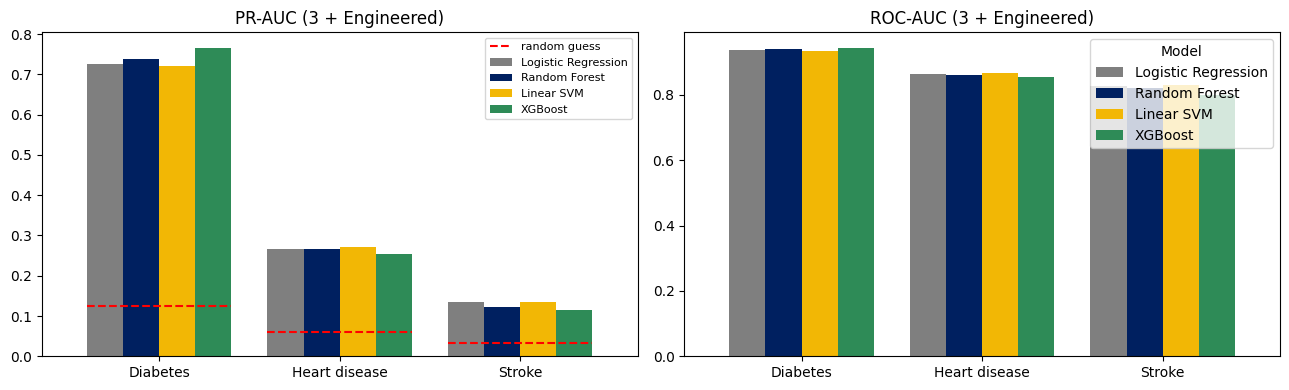

In [ ]:
last = results[results["Features"] == FS[2]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["PR-AUC", "ROC-AUC"]):
    piv = last.pivot(index="Disease", columns="Model", values=metric).loc[TARGETS, names]
    piv.plot.bar(ax=ax, color=[COLORS[n] for n in names], width=0.8)
    ax.set_title(f"{metric} ({FS[2]})"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
    if metric == "PR-AUC":
        for i, t in enumerate(TARGETS):
            ax.hlines(df[t].mean(), i-0.4, i+0.4, colors="red", linestyles="--", linewidth=1.5, label="random guess" if i == 0 else None)
        ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("chart_1_models.png", dpi=150); plt.show()

### Chart 2: what do lab tests and engineered features add?

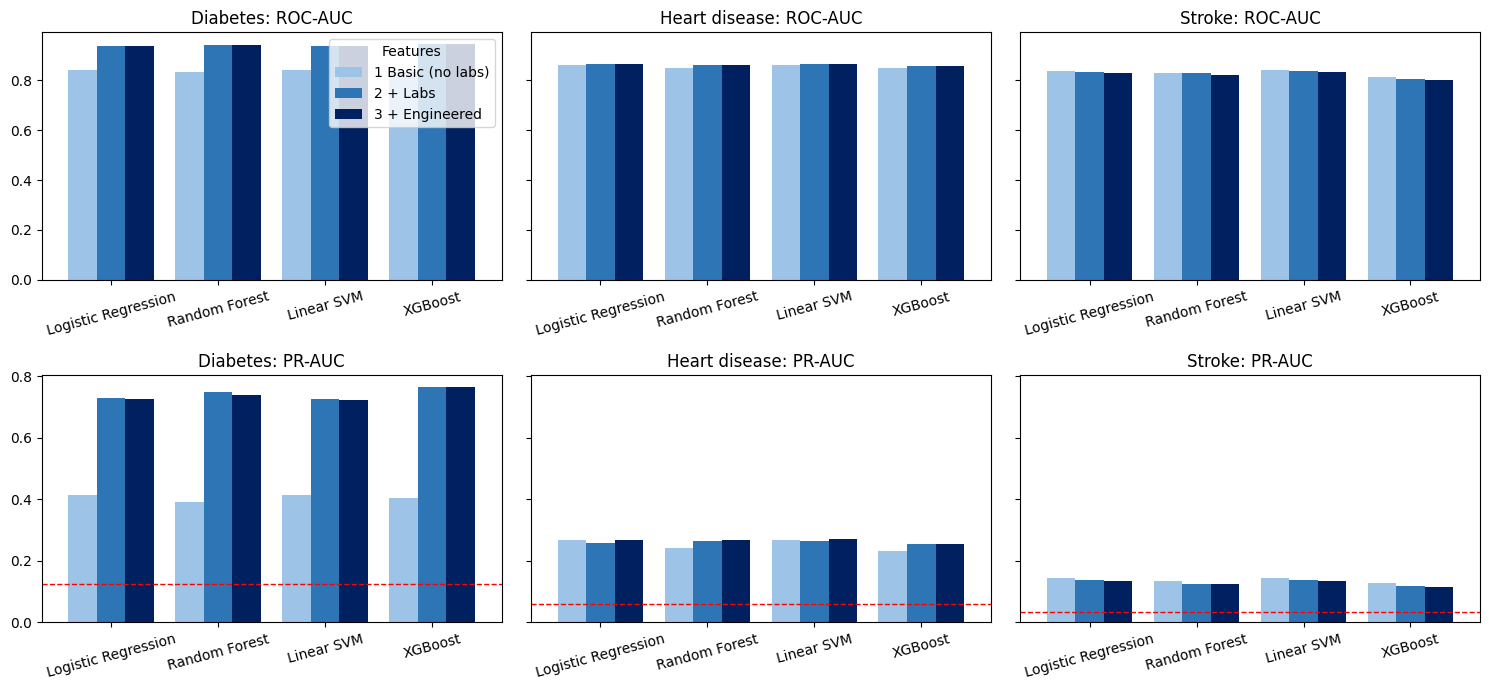

Average gain from adding features (mean over the 4 models):


ROC-AUC                                    PR-AUC                        
Features      1 Basic (no labs) 2 + Labs 3 + Engineered 1 Basic (no labs) 2 + Labs 3 + Engineered
Disease                                                                                          
Diabetes                  0.837    0.940          0.940             0.406    0.742          0.738
Heart disease             0.854    0.862          0.863             0.252    0.261          0.265
Stroke                    0.829    0.825          0.820             0.137    0.130          0.127

In [ ]:
FS_COLORS = dict(zip(FS, ["#9DC3E6", "#2E75B6", "#002060"]))
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey="row")
for r, metric in enumerate(["ROC-AUC", "PR-AUC"]):
    for c, target in enumerate(TARGETS):
        ax = axes[r, c]
        sub = results[results["Disease"] == target]
        piv = sub.pivot(index="Model", columns="Features", values=metric).loc[names, FS]
        piv.plot.bar(ax=ax, color=[FS_COLORS[f] for f in FS], width=0.8, legend=(r == 0 and c == 0))
        ax.set_title(f"{target}: {metric}"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=15)
        if metric == "PR-AUC": ax.axhline(df[target].mean(), color="red", ls="--", lw=1)
plt.tight_layout(); plt.savefig("chart_2_feature_sets.png", dpi=150); plt.show()

print("Average gain from adding features (mean over the 4 models):")
g = results.groupby(["Disease", "Features"])[["ROC-AUC", "PR-AUC"]].mean().unstack("Features").round(3)
display(g)

### Chart 3: ROC and Precision-Recall curves (best feature set)

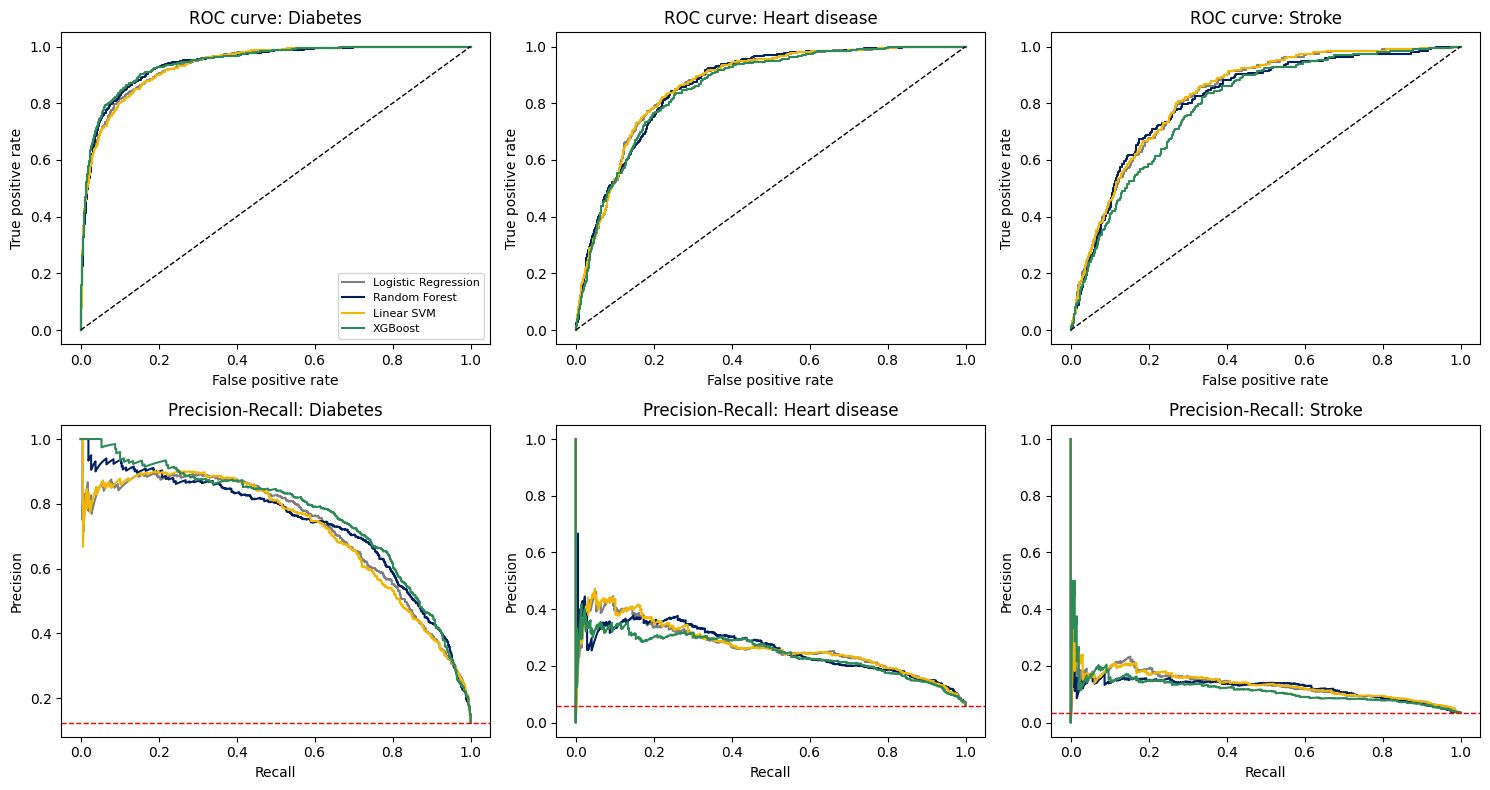

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, target in enumerate(TARGETS):
    for name in names:
        y, s = curves[(FS[2], target, name)]
        fpr, tpr, _ = roc_curve(y, s);          axes[0, j].plot(fpr, tpr, color=COLORS[name], label=name)
        p, r_, _ = precision_recall_curve(y, s); axes[1, j].plot(r_, p, color=COLORS[name], label=name)
    axes[0, j].plot([0, 1], [0, 1], "k--", lw=1); axes[0, j].set_title(f"ROC curve: {target}")
    axes[0, j].set_xlabel("False positive rate"); axes[0, j].set_ylabel("True positive rate")
    axes[1, j].axhline(df[target].mean(), color="red", ls="--", lw=1); axes[1, j].set_title(f"Precision-Recall: {target}")
    axes[1, j].set_xlabel("Recall"); axes[1, j].set_ylabel("Precision")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("chart_3_curves.png", dpi=150); plt.show()

### Chart 4: most important features (XGBoost trained on all people)

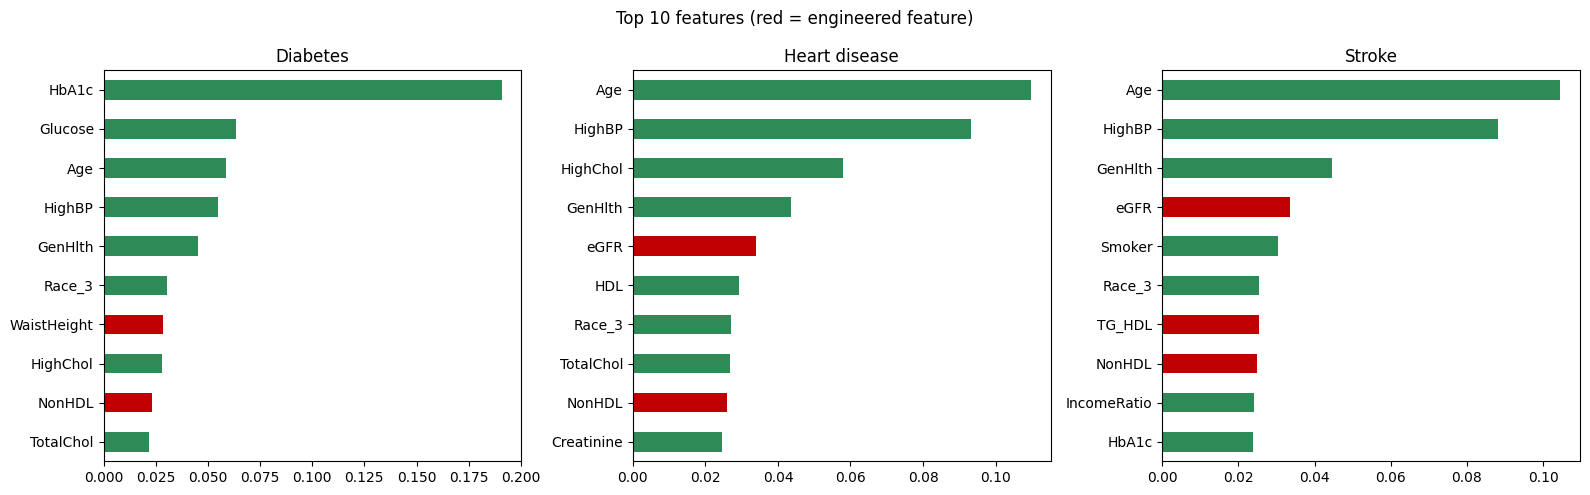

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
cols = FEATURE_SETS[FS[2]]
for ax, target in zip(axes, TARGETS):
    y = df[target].values
    pipe = make_pipeline(XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=5, subsample=0.8,
                                       colsample_bytree=0.8, scale_pos_weight=(y == 0).sum() / (y == 1).sum(),
                                       tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE), cols, scale=False)
    pipe.fit(df[cols], y)
    names_out = pipe.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=[n.split("__")[-1] for n in names_out]).sort_values().tail(10)
    imp.plot.barh(ax=ax, color=["#C00000" if n in ENG else "#2E8B57" for n in imp.index]); ax.set_title(f"{target}")
fig.suptitle("Top 10 features (red = engineered feature)", fontsize=12)
plt.tight_layout(); plt.savefig("chart_4_importance.png", dpi=150); plt.show()

## 8. NHANES vs BRFSS (the first dataset)

The BRFSS numbers below are the test-set results from our previous notebook (same 4 models).

Be careful: the two datasets have **different people, different sizes and different test methods** (BRFSS: one test set of 34,000 people; NHANES: cross-validation on 5,700 adults). So this is a comparison of the **general picture**, not an exact race.
PR-AUC depends on how common the disease is, so we also show the **lift** = PR-AUC divided by the disease rate (how many times better than random guessing).

In [ ]:
# BRFSS results from the previous notebook: (ROC-AUC, PR-AUC) on the test set, and disease rates
BRFSS = {
    "Logistic Regression": {"Diabetes": (0.806, 0.410), "Heart disease": (0.822, 0.343), "Stroke": (0.800, 0.154)},
    "Random Forest":       {"Diabetes": (0.812, 0.425), "Heart disease": (0.822, 0.342), "Stroke": (0.794, 0.149)},
    "Linear SVM":          {"Diabetes": (0.806, 0.410), "Heart disease": (0.822, 0.343), "Stroke": (0.800, 0.155)},
    "XGBoost":             {"Diabetes": (0.816, 0.435), "Heart disease": (0.825, 0.353), "Stroke": (0.801, 0.158)},
}
BRFSS_RATE = {"Diabetes": 0.153, "Heart disease": 0.103, "Stroke": 0.045}

rows = []
for target in TARGETS:
    for name in names:
        b_roc, b_pr = BRFSS[name][target]
        row = {"Disease": target, "Model": name, "BRFSS ROC-AUC": b_roc, "BRFSS PR-AUC": b_pr, "BRFSS lift": b_pr / BRFSS_RATE[target]}
        for tag, fs in [("NHANES no labs", FS[0]), ("NHANES all", FS[2])]:
            r = results[(results["Disease"] == target) & (results["Model"] == name) & (results["Features"] == fs)].iloc[0]
            row[f"{tag} ROC-AUC"], row[f"{tag} PR-AUC"], row[f"{tag} lift"] = r["ROC-AUC"], r["PR-AUC"], r["PR-AUC"] / df[target].mean()
        rows.append(row)
cmp_ = pd.DataFrame(rows)
display(cmp_.set_index(["Disease", "Model"]).round(3))

BRFSS ROC-AUC  BRFSS PR-AUC  BRFSS lift  NHANES no labs ROC-AUC  NHANES no labs PR-AUC  NHANES no labs lift  NHANES all ROC-AUC  NHANES all PR-AUC  NHANES all lift
Disease       Model                                                                                                                                                                                   
Diabetes      Logistic Regression          0.806         0.410       2.680                   0.840                  0.415                3.336               0.937              0.726            5.835
              Random Forest                0.812         0.425       2.778                   0.832                  0.392                3.152               0.941              0.739            5.945
              Linear SVM                   0.806         0.410       2.680                   0.840                  0.415                3.334               0.936              0.722            5.807
              XGBoost                      0.816         0.435       2.843                   0.835                  0.403                3.243               0.945              0.766            6.162
Heart disease Logistic Regression          0.822         0.343       3.330                   0.860                  0.266                4.443               0.866              0.267            4.462
              Random Forest                0.822         0.342       3.320                   0.847                  0.241                4.021               0.862              0.268            4.466
              Linear SVM                   0.822         0.343       3.330                   0.860                  0.268                4.473               0.866              0.270            4.515
              XGBoost                      0.825         0.353       3.427                   0.848                  0.232                3.880               0.856              0.254            4.247
Stroke        Logistic Regression          0.800         0.154       3.422                   0.839                  0.143                4.203               0.829              0.134            3.921
              Random Forest                0.794         0.149       3.311                   0.827                  0.134                3.920               0.821              0.123            3.610
              Linear SVM                   0.800         0.155       3.444                   0.839                  0.143                4.198               0.832              0.136            3.972
              XGBoost                      0.801         0.158       3.511                   0.812                  0.127                3.710               0.800              0.114            3.348

### Chart 5: final comparison, BRFSS vs NHANES

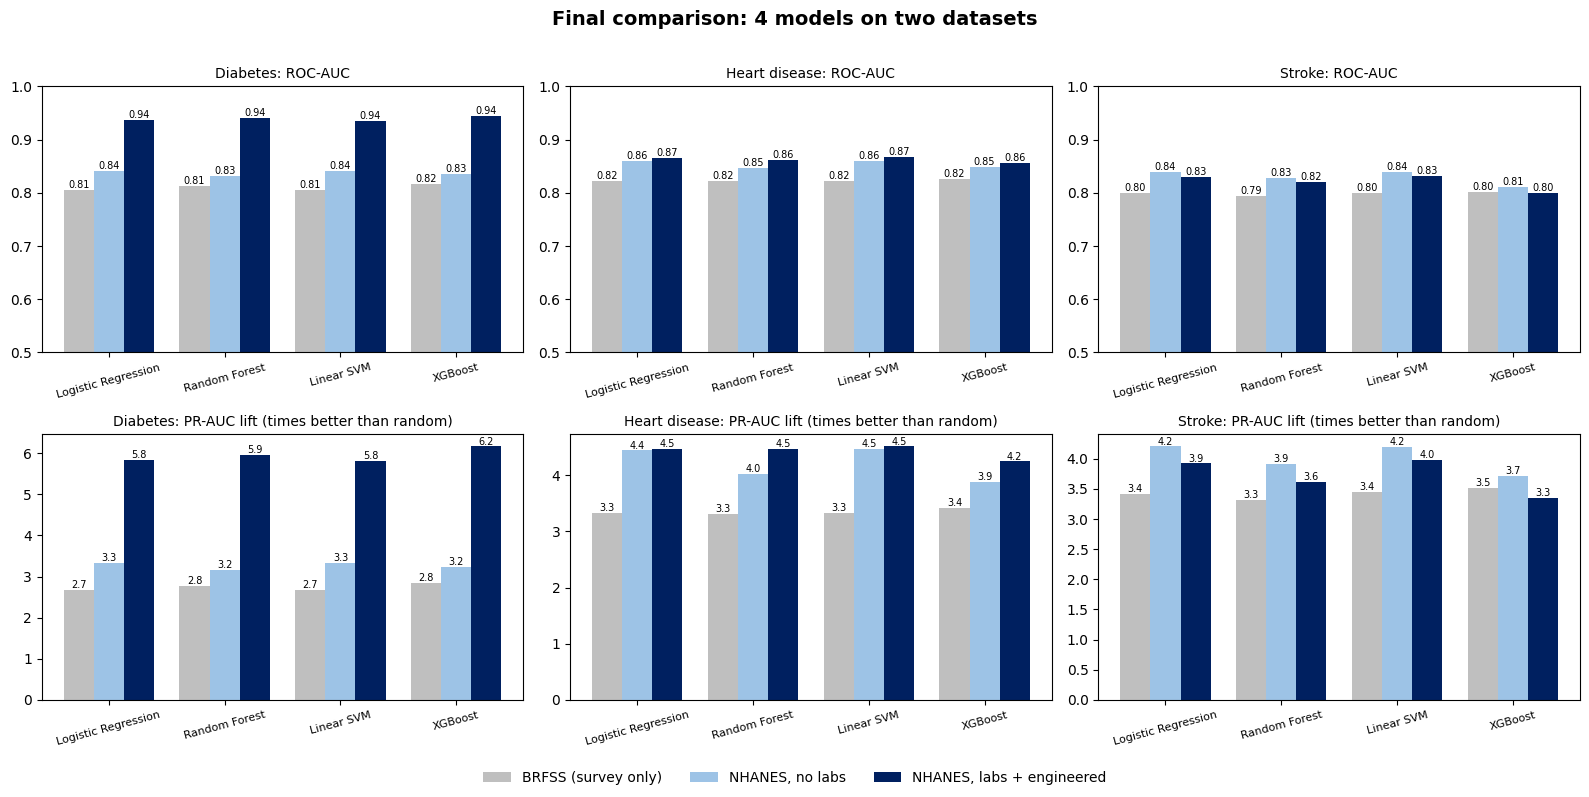

In [ ]:
SRC = [("BRFSS (survey only)", "BRFSS", "#BFBFBF"), ("NHANES, no labs", "NHANES no labs", "#9DC3E6"), ("NHANES, labs + engineered", "NHANES all", "#002060")]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for c, target in enumerate(TARGETS):
    sub = cmp_[cmp_["Disease"] == target].set_index("Model").loc[names]
    for r, (metric, label) in enumerate([("ROC-AUC", "ROC-AUC"), ("lift", "PR-AUC lift (times better than random)")]):
        ax = axes[r, c]; x = np.arange(len(names)); w = 0.26
        for i, (lab, key, col) in enumerate(SRC):
            vals = sub[f"{key} {metric}"].values
            bars = ax.bar(x + (i - 1) * w, vals, w, color=col, label=lab)
            for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}" if metric == "ROC-AUC" else f"{v:.1f}", ha="center", va="bottom", fontsize=7)
        ax.set_xticks(x); ax.set_xticklabels(names, rotation=15, fontsize=8); ax.set_title(f"{target}: {label}", fontsize=10)
        if metric == "ROC-AUC": ax.set_ylim(0.5, 1.0)
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, fontsize=10, frameon=False)
fig.suptitle("Final comparison: 4 models on two datasets", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0.04, 1, 0.97]); plt.savefig("chart_5_brfss_vs_nhanes.png", dpi=150); plt.show()

## 9. Save everything

In [ ]:
os.makedirs("results_nhanes", exist_ok=True)
results.round(4).to_csv("results_nhanes/nhanes_model_results.csv", index=False)
cmp_.round(4).to_csv("results_nhanes/brfss_vs_nhanes.csv", index=False)
auc_table.to_csv("results_nhanes/feature_engineering_auc.csv")
df.to_csv("results_nhanes/nhanes_adults_prepared.csv", index=False)       # the dataset we built (for later use)
for f in os.listdir("."):
    if f.startswith("chart_") and f.endswith(".png"): shutil.move(f, f"results_nhanes/{f}")
shutil.make_archive("results_nhanes", "zip", "results_nhanes")
print("Saved:", sorted(os.listdir("results_nhanes")))
try:
    from google.colab import files
    files.download("results_nhanes.zip")
except ImportError:
    pass